# Proyecto integrador YOLO26 — Notebook 01: Dataset y entrenamiento
**Clases:** `0 = mate`, `1 = termo`. **Entorno:** Google Colab Pro con GPU.  
Este notebook prepara y valida un dataset **anotado realmente por el grupo**, entrena YOLO26 mediante *transfer learning* y guarda `best.pt` y métricas. **No incluye imágenes ni etiquetas inventadas.**

**Flujo:** 1) Instalar y conectar Drive → 2) Reunir fotografías o extraer fotogramas → 3) Anotar externamente (MakeSense/Roboflow/CVAT) → 4) Validar y dividir → 5) Entrenar y evaluar → 6) Exportar.

La primera ejecución se detendrá de forma intencional cuando no existan imágenes etiquetadas. Seguir el bloque «Paso manual de anotación» para completar esa etapa.

## 1. Instalación y configuración del entorno
En Colab: **Entorno de ejecución → Cambiar tipo de entorno de ejecución → GPU**. La disponibilidad exacta de GPU depende de Colab.

In [1]:
%pip -q install -U "ultralytics>=8.4" pandas matplotlib scikit-learn


Note: you may need to restart the kernel to use updated packages.


In [2]:
import hashlib
import json
import os
import random
import shutil
import sys
import zipfile
from pathlib import Path

import cv2
import matplotlib.patches as patches
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
import yaml
from IPython.display import Image as IPyImage
from IPython.display import display
from PIL import Image, ImageOps
from sklearn.model_selection import GroupShuffleSplit
from ultralytics import YOLO

IN_COLAB = 'google.colab' in sys.modules or os.path.exists('/content')


def resolve_root() -> Path:
    """Devuelve la raíz del proyecto según el entorno de ejecución.

    En Colab monta Google Drive y usa ``MyDrive/Proyecto_Integrador_YOLO26``
    si existe; si no, ``/content/CV-mate-detection``. En local usa el
    directorio padre cuando el notebook corre desde ``notebooks/``.

    Returns:
        Directorio raíz del repositorio.
    """
    if not IN_COLAB:
        cwd = Path.cwd()
        return cwd.parent if cwd.name == 'notebooks' else cwd
    colab_repo = Path('/content/CV-mate-detection')
    try:
        from google.colab import drive

        drive.mount('/content/drive')
    except Exception as exc:  # noqa: BLE001 - Drive es opcional.
        print('Advertencia al montar Drive:', exc)
        return colab_repo if colab_repo.exists() else Path.cwd()
    drive_root = Path('/content/drive/MyDrive/Proyecto_Integrador_YOLO26')
    return drive_root if drive_root.exists() else colab_repo


ROOT = resolve_root()
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

RAW = ROOT / 'dataset'
LABELS = ROOT / 'data' / 'unified' / 'labels'
SOURCE_VIDEOS = ROOT / 'videos' / 'fuente_dataset'
DATASET = ROOT / 'dataset_yolo26_mate_termo'
RUNS = ROOT / 'entrenamientos'
for folder in (RAW, LABELS, SOURCE_VIDEOS, RUNS):
    folder.mkdir(parents=True, exist_ok=True)

CLASSES = {0: 'mate', 1: 'termo'}
IMAGE_SUFFIXES = {'.jpg', '.jpeg', '.png', '.webp'}

print('=== ENTORNO DE EJECUCIÓN ===')
print('Modo Colab:', IN_COLAB)
print('Directorio raíz (ROOT):', ROOT)
print('Directorio de imágenes (RAW):', RAW)
print('Directorio de etiquetas (LABELS):', LABELS)
print('GPU:', torch.cuda.get_device_name(0) if torch.cuda.is_available()
      else 'No disponible (CPU)')
print('Ultralytics:', __import__('ultralytics').__version__)


=== ENTORNO DE EJECUCIÓN ===
Modo Colab: False
Directorio raíz (ROOT): c:\Users\bruno.pace\Documents\UGR\CV\CV-mate-detection
Directorio de imágenes (RAW): c:\Users\bruno.pace\Documents\UGR\CV\CV-mate-detection\dataset
Directorio de etiquetas (LABELS): c:\Users\bruno.pace\Documents\UGR\CV\CV-mate-detection\data\unified\labels
GPU: NVIDIA RTX PRO 500 Blackwell Generation Laptop GPU
Ultralytics: 8.4.202


## 2. Recolección de imágenes y trazabilidad
**Meta sugerida:** al menos 100 fotografías originales por clase, de distintas fuentes y condiciones. No usar 100 fotogramas casi idénticos del mismo video como si fueran 100 observaciones independientes.

1. Reunir fotografías de uso permitido; guardar originales en `dataset/`.
2. Registrar URL/autor/licencia/fecha en `fuentes_dataset.csv` (plantilla incluida en la entrega).
3. Si hay videos descargados legítimamente para extraer cuadros, colocarlos en `videos_fuente_dataset/`.
4. Convención recomendable: `fuente01__f00000120.jpg` para cuadros de una misma fuente. El prefijo antes de `__` servirá para evitar que cuadros del mismo video caigan en train y test.

**Consejo de diversidad:** distintos recipientes de mate, bombillas, termos, fondos, distancias, iluminación, oclusión, interiores/exteriores y fotos con ambos objetos. Incluir algunas imágenes negativas (sin mate ni termo), si están justificadas.

No descargar imágenes masivamente de buscadores sin comprobar condiciones de uso.

### 2.1. Opcional: extraer fotogramas de videos de origen
La celda guarda un fotograma cada ~2 segundos por video; sus etiquetas **aún deben anotarse manualmente**. Evitar versiones duplicadas del mismo video como distintas fuentes.

In [3]:
EXTRAER_FOTOGRAMAS = False  # True cuando haya videos en SOURCE_VIDEOS
INTERVALO_SEGUNDOS = 2.0


def extract_frames(video: Path, out_dir: Path, interval_s: float) -> int:
    """Guarda un fotograma cada ``interval_s`` segundos de un video.

    Los archivos se nombran ``<video>__f<nro>.jpg``: el prefijo antes de
    ``__`` agrupa los cuadros de un mismo video en el split.

    Args:
        video: Video de origen.
        out_dir: Carpeta donde guardar los fotogramas.
        interval_s: Segundos entre fotogramas guardados.

    Returns:
        Cantidad de fotogramas nuevos escritos.
    """
    cap = cv2.VideoCapture(str(video))
    fps = cap.get(cv2.CAP_PROP_FPS)
    if fps <= 0:
        cap.release()
        print('Se omite (FPS inválido):', video.name)
        return 0
    step = max(1, round(fps * interval_s))
    frame_id = 0
    generated = 0
    while True:
        ok, frame = cap.read()
        if not ok:
            break
        target = out_dir / f'{video.stem}__f{frame_id:08d}.jpg'
        if frame_id % step == 0 and not target.exists():
            cv2.imwrite(str(target), frame, [cv2.IMWRITE_JPEG_QUALITY, 92])
            generated += 1
        frame_id += 1
    cap.release()
    return generated


if EXTRAER_FOTOGRAMAS:
    for video in sorted(SOURCE_VIDEOS.glob('*.mp4')):
        nuevos = extract_frames(video, RAW, INTERVALO_SEGUNDOS)
        print(video.name, 'nuevos fotogramas:', nuevos)
n_raw = sum(p.suffix.lower() in IMAGE_SUFFIXES for p in RAW.iterdir())
print('Imágenes sin particionar:', n_raw)


Imágenes sin particionar: 90


## 3. Paso manual: anotación real en YOLO
En [MakeSense.ai](https://www.makesense.ai/) o herramienta equivalente:

1. Cargar las imágenes de `dataset/`.
2. Crear **en este orden exacto** las etiquetas `mate` (ID 0), `termo` (ID 1).
3. Dibujar bounding boxes ajustadas a los límites visibles de los objetos. Marcar todas las instancias de ambas clases; sin cajas para objetos que no pertenecen a estas dos clases.
4. Exportar etiquetas YOLO Detection (archivos `.txt` por imagen); descomprimirlas y subirlas a `data/unified/labels/`.
5. Revisar cualquier `classes.txt` exportado y su orden. Debe contener `mate` y `termo`, en ese orden. Si no coincide, corregir el mapeo antes de seguir.
6. Cada imagen con un objeto de interés debe tener su `.txt`. Para una imagen negativa puede crear un `.txt` vacío, explicitando que no hay clases objetivo.

**Importante:** para descargar las imágenes de Drive y cargarlas al anotador, puede comprimir la carpeta desde Colab con la siguiente celda. Los navegadores no ofrecen acceso directo universal a archivos del Drive montado.

In [4]:
# Opcional: ZIP de fotografías para importar en la herramienta de anotación.
CREAR_ZIP_PARA_ETIQUETAR = False
if CREAR_ZIP_PARA_ETIQUETAR:
    destino = ROOT / 'imagenes_para_etiquetar.zip'
    with zipfile.ZipFile(destino, 'w', compression=zipfile.ZIP_DEFLATED) as zf:
        for file in sorted(RAW.iterdir()):
            if file.suffix.lower() in IMAGE_SUFFIXES:
                zf.write(file, file.name)
    print('ZIP creado:', destino)


## 4. Validación estricta de etiquetas y fuentes
El entrenamiento NO comienza si: no hay suficientes imágenes por clase, faltan etiquetas, hay etiquetas fuera de rango o hay nombres de clases incompatibles. Las imágenes duplicadas se señalan por hash. El criterio de 50 se aplica a **imágenes únicas que contienen cada clase**, no al número de cajas.

In [5]:
MIN_IMAGENES_POR_CLASE = 50
MIN_GRUPOS = 10


class DatasetError(ValueError):
    """El dataset no cumple los requisitos para entrenar."""


def read_yolo_label(label_path: Path) -> list[int]:
    """Lee y valida un archivo de etiquetas YOLO.

    Args:
        label_path: Archivo ``.txt`` con una caja por línea.

    Returns:
        IDs de clase de cada caja (vacía si es una imagen negativa).

    Raises:
        ValueError: Si alguna línea no tiene 5 columnas, la clase no existe o
            la caja sale del área normalizada.
    """
    eps = 1e-4
    class_ids = []
    text = label_path.read_text(encoding='utf-8-sig')
    for lineno, line in enumerate(text.splitlines(), start=1):
        if not line.strip():
            continue
        parts = line.split()
        if len(parts) != 5:
            raise ValueError(f'línea {lineno}: se requieren 5 columnas')
        cls_raw = float(parts[0])
        cls = int(cls_raw)
        if cls_raw != cls or cls not in CLASSES:
            raise ValueError(f'línea {lineno}: clase inválida {parts[0]}')
        x, y, w, h = map(float, parts[1:])
        if not np.all(np.isfinite([x, y, w, h])):
            raise ValueError(f'línea {lineno}: valores no finitos')
        if not (0 < w <= 1 + eps and 0 < h <= 1 + eps):
            raise ValueError(f'línea {lineno}: ancho/alto inválido')
        inside = (-eps <= x - w / 2 and x + w / 2 <= 1 + eps
                  and -eps <= y - h / 2 and y + h / 2 <= 1 + eps)
        if not inside:
            raise ValueError(f'línea {lineno}: caja fuera de la imagen')
        class_ids.append(cls)
    return class_ids


def image_digest(image_path: Path) -> str:
    """Calcula un hash de los píxeles decodificados de una imagen.

    Detecta duplicados aunque los archivos difieran en metadatos o
    compresión.

    Args:
        image_path: Imagen a procesar.

    Returns:
        SHA-256 de los píxeles RGB y del tamaño.

    Raises:
        ValueError: Si la imagen mide menos de 64 px de lado.
        OSError: Si la imagen está corrupta.
    """
    with Image.open(image_path) as img:
        img.verify()
    with Image.open(image_path) as img:
        if img.width < 64 or img.height < 64:
            raise ValueError('dimensiones muy pequeñas')
        payload = img.convert('RGB').tobytes() + f'{img.size}'.encode()
    return hashlib.sha256(payload).hexdigest()


def build_records(
    images: list[Path], labels_dir: Path,
) -> tuple[list[dict], list[str], list[str]]:
    """Empareja imágenes con etiquetas y valida ambas.

    El grupo de cada imagen es el prefijo antes de ``__`` (fotogramas de un
    mismo video) o el nombre completo si no lo tiene.

    Args:
        images: Imágenes candidatas.
        labels_dir: Carpeta con los ``.txt`` YOLO.

    Returns:
        ``(records, unlabeled, errors)``. Cada record tiene ``image``,
        ``label``, ``group``, ``class_ids`` y ``boxes``.
    """
    records = []
    unlabeled = []
    errors = []
    seen_hashes = {}
    for image in images:
        label = labels_dir / f'{image.stem}.txt'
        if not label.is_file():
            unlabeled.append(image.name)
            continue
        try:
            digest = image_digest(image)
        except Exception as exc:  # noqa: BLE001 - se reporta cualquier fallo.
            errors.append(f'Imagen ilegible: {image.name}: {exc}')
            continue
        if digest in seen_hashes:
            errors.append(f'Imagen duplicada: {image.name} y '
                          f'{seen_hashes[digest]}')
            continue
        seen_hashes[digest] = image.name
        try:
            class_ids = read_yolo_label(label)
        except ValueError as exc:
            errors.append(f'{label.name}: {exc}')
            continue
        group = image.stem.split('__', 1)[0]
        records.append({'image': image, 'label': label, 'group': group,
                        'class_ids': set(class_ids), 'boxes': len(class_ids)})
    return records, unlabeled, errors


images = sorted(p for p in RAW.iterdir()
                if p.is_file() and p.suffix.lower() in IMAGE_SUFFIXES)
if not images:
    raise DatasetError(f'Faltan imágenes. Colocarlas en {RAW} (sección 2).')
stems = [p.stem for p in images]
if len(stems) != len(set(stems)):
    raise DatasetError('Hay imágenes con el mismo nombre y distinta '
                       'extensión; renombrarlas.')

classes_file = LABELS / 'classes.txt'
if classes_file.exists():
    declared = [s.strip().lower() for s in
                classes_file.read_text(encoding='utf-8-sig').splitlines()
                if s.strip()]
    if declared != list(CLASSES.values()):
        raise DatasetError(f'Orden de clases incorrecto: {declared}. '
                           'Se requiere mate, termo.')

records, unlabeled_images, errors = build_records(images, LABELS)
if unlabeled_images:
    print(f'[AVISO] {len(unlabeled_images)} imágenes sin .txt (se omiten):',
          unlabeled_images)
if errors:
    print('\n'.join(errors[:30]))
    raise DatasetError(f'Corregir los {len(errors)} problemas antes de '
                       'continuar.')

counts = {name: sum(idx in rec['class_ids'] for rec in records)
          for idx, name in CLASSES.items()}
n_groups = len({rec['group'] for rec in records})
print('=== RESUMEN DEL DATASET VALIDADO ===')
print('Imágenes con cada clase:', counts)
print('Imágenes únicas procesables:', len(records), '| grupos/fuentes:',
      n_groups)

faltantes = {name: MIN_IMAGENES_POR_CLASE - n for name, n in counts.items()
             if n < MIN_IMAGENES_POR_CLASE}
if faltantes:
    print('[ADVERTENCIA] El enunciado exige al menos '
          f'{MIN_IMAGENES_POR_CLASE} imágenes por clase. Faltan: {faltantes}')
if n_groups < MIN_GRUPOS:
    raise DatasetError(f'Hay menos de {MIN_GRUPOS} fuentes independientes. '
                       'Reunir más diversidad.')


=== RESUMEN DEL DATASET VALIDADO ===
Imágenes con cada clase: {'mate': 60, 'termo': 50}
Imágenes únicas procesables: 90 | grupos/fuentes: 90


## 5. Inspección visual de las etiquetas
La validación numérica no reemplaza la revisión manual. Las cajas deben ajustarse a los objetos y todas las instancias deberían estar etiquetadas.

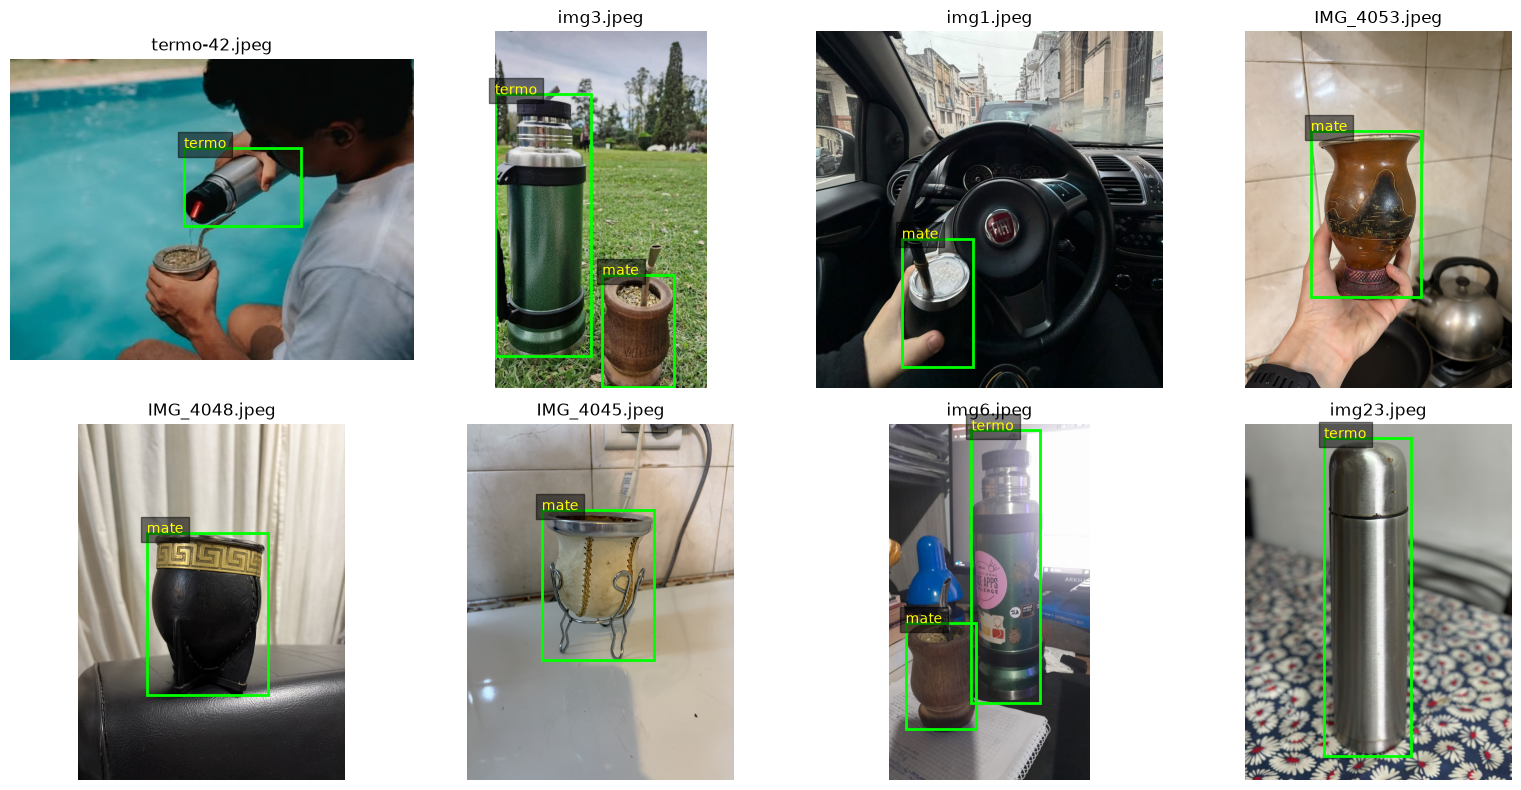

In [6]:
def plot_labeled_samples(records: list[dict], k: int = 8) -> None:
    """Muestra ``k`` imágenes al azar con sus cajas dibujadas.

    Args:
        records: Records devueltos por ``build_records``.
        k: Cantidad de imágenes a mostrar (máximo 8).
    """
    sample = random.sample(records, k=min(k, len(records), 8))
    fig, axs = plt.subplots(2, 4, figsize=(16, 8))
    axs = axs.ravel()
    for ax, rec in zip(axs, sample, strict=False):
        with Image.open(rec['image']) as img:
            im = ImageOps.exif_transpose(img).convert('RGB')
        ax.imshow(im)
        ww, hh = im.size
        for line in rec['label'].read_text().splitlines():
            if not line.strip():
                continue
            cls, xc, yc, bw, bh = map(float, line.split())
            x0 = (xc - bw / 2) * ww
            y0 = (yc - bh / 2) * hh
            ax.add_patch(patches.Rectangle((x0, y0), bw * ww, bh * hh,
                                           fill=False, edgecolor='lime',
                                           linewidth=2))
            ax.text(x0, max(2, y0), CLASSES[int(cls)], color='yellow',
                    bbox={'facecolor': 'black', 'alpha': 0.5})
        ax.set_title(rec['image'].name[:28])
        ax.axis('off')
    for ax in axs[len(sample):]:
        ax.axis('off')
    fig.tight_layout()
    plt.show()


plot_labeled_samples(records)


## 6. División train/val/test agrupada y reproducible
Se utiliza una división 80/10/10 **por grupo de origen**, evitando que fotogramas del mismo video estén en conjuntos diferentes. La distribución por clases debe verificarse luego: si algún conjunto queda sin una clase, se detiene la ejecución para ajustar fuentes o división. Si ya existe una partición definida externamente, adaptar este bloque para respetarla.

Nota: el resultado se recrea dentro de `dataset_yolo26_mate_termo/`.

In [7]:
HOLDOUT = 0.20  # fracción para val + test (se divide en partes iguales)


def grouped_split(records: list[dict], holdout: float,
                  seed: int) -> dict[str, list[dict]]:
    """Divide los records en train/val/test sin repartir un grupo entre splits.

    Args:
        records: Records con la clave ``group``.
        holdout: Fracción de grupos para val + test.
        seed: Semilla de ``GroupShuffleSplit``.

    Returns:
        Records de ``train``, ``val`` y ``test``.
    """
    indices = np.arange(len(records))
    groups = [rec['group'] for rec in records]
    gss = GroupShuffleSplit(n_splits=1, test_size=holdout, random_state=seed)
    train_idx, hold_idx = next(gss.split(indices, groups=groups))
    hold_groups = [groups[i] for i in hold_idx]
    gss_half = GroupShuffleSplit(n_splits=1, test_size=0.5, random_state=seed)
    val_rel, test_rel = next(gss_half.split(hold_idx, groups=hold_groups))
    return {
        'train': [records[i] for i in train_idx],
        'val': [records[hold_idx[i]] for i in val_rel],
        'test': [records[hold_idx[i]] for i in test_rel],
    }


def summarize_splits(splits: dict[str, list[dict]]) -> pd.DataFrame:
    """Cuenta imágenes, grupos e imágenes por clase de cada split.

    Args:
        splits: Salida de ``grouped_split``.

    Returns:
        Una fila por split.
    """
    rows = []
    for split, subset in splits.items():
        row = {'split': split, 'total': len(subset),
               'grupos': len({rec['group'] for rec in subset})}
        row.update({name: sum(i in rec['class_ids'] for rec in subset)
                    for i, name in CLASSES.items()})
        rows.append(row)
    return pd.DataFrame(rows)


def write_yolo_dataset(splits: dict[str, list[dict]],
                       dataset_dir: Path) -> Path:
    """Copia imágenes y etiquetas a la estructura YOLO y escribe data.yaml.

    Borra ``dataset_dir`` antes de escribir.

    Args:
        splits: Salida de ``grouped_split``.
        dataset_dir: Carpeta destino.

    Returns:
        Ruta del ``data.yaml`` generado.
    """
    if dataset_dir.exists():
        shutil.rmtree(dataset_dir)
    for split, subset in splits.items():
        image_dir = dataset_dir / 'images' / split
        label_dir = dataset_dir / 'labels' / split
        image_dir.mkdir(parents=True)
        label_dir.mkdir(parents=True)
        for rec in subset:
            shutil.copy2(rec['image'], image_dir / rec['image'].name)
            shutil.copy2(rec['label'], label_dir / rec['label'].name)
    config = {'path': str(dataset_dir), 'train': 'images/train',
              'val': 'images/val', 'test': 'images/test', 'names': CLASSES}
    data_yaml = dataset_dir / 'data.yaml'
    data_yaml.write_text(yaml.safe_dump(config, sort_keys=False,
                                        allow_unicode=True), encoding='utf-8')
    return data_yaml


splits = grouped_split(records, HOLDOUT, SEED)
df_summary = summarize_splits(splits)
display(df_summary)
if (df_summary[list(CLASSES.values())] < 1).to_numpy().any():
    raise DatasetError('Una clase quedó ausente de train, val o test. '
                       'Hacen falta más fuentes o cambiar el split.')
DATA_YAML = write_yolo_dataset(splits, DATASET)
df_summary.to_csv(DATASET / 'recuento_split.csv', index=False)
print(DATA_YAML.read_text(encoding='utf-8'))


,split,total,grupos,mate,termo
0,train,72,72,48,41
1,val,9,9,6,5
2,test,9,9,6,4


path: c:\Users\bruno.pace\Documents\UGR\CV\CV-mate-detection\dataset_yolo26_mate_termo
train: images/train
val: images/val
test: images/test
names:
  0: mate
  1: termo



## 7. Transfer Learning con YOLO26
YOLO26 Detection ajusta los pesos preentrenados en COCO a dos clases nuevas. Se parte de `yolo26n.pt` (variante *nano*, la más liviana) con hasta 120 épocas y *early stopping* (paciencia 15); no se afirma que estos hiperparámetros sean óptimos.

**Persistencia:** los resultados/checkpoints van directamente a Google Drive. Esto suele ser algo más lento que `/content`, pero protege el progreso de desconexiones. La carpeta de corrida es única por defecto. Para reanudar, activar `REANUDAR` y señalar `last.pt`.

In [ ]:
EPOCHS = 120
IMGSZ = 640
BATCH = 16
PATIENCE = 15

# Pesos YOLO26 nano preentrenados en COCO; Ultralytics >= 8.4 los descarga.
MODEL_BASE = 'yolo26n.pt'
RUN_NAME = 'mate_termo_yolo26'
REANUDAR = False
ULTIMO_CHECKPOINT = RUNS / RUN_NAME / 'weights' / 'last.pt'
DEVICE = 0 if torch.cuda.is_available() else 'cpu'

if DEVICE == 'cpu':
    if IN_COLAB:
        raise RuntimeError('Habilitar GPU en Colab: Entorno de ejecución → '
                           'Cambiar tipo de entorno → T4 GPU.')
    print('[ADVERTENCIA] Sin CUDA: el entrenamiento correrá en CPU.')

if REANUDAR:
    if not ULTIMO_CHECKPOINT.exists():
        raise FileNotFoundError(ULTIMO_CHECKPOINT)
    detector = YOLO(str(ULTIMO_CHECKPOINT))
    train_results = detector.train(resume=True)
else:
    detector = YOLO(MODEL_BASE)
    train_results = detector.train(
        data=str(DATA_YAML), epochs=EPOCHS, imgsz=IMGSZ, batch=BATCH,
        patience=PATIENCE, seed=SEED, device=DEVICE, project=str(RUNS),
        name=RUN_NAME, exist_ok=True, save=True, plots=True, workers=2,
    )

BEST = RUNS / RUN_NAME / 'weights' / 'best.pt'
if not BEST.exists():
    raise FileNotFoundError('No se generó best.pt: revisar el entrenamiento.')
print('Pesos entrenados guardados en:', BEST)


## 8. Evaluación cuantitativa final en test
**No confundir validación con test.** Durante el entrenamiento se utiliza `val`; la evaluación final utiliza imágenes `test` no empleadas en el ajuste. Las métricas se calculan en esta ejecución, nunca se inventan.

Se reportan P, R, **F1** y mAP. La matriz de confusión se genera en una segunda pasada con `conf=0.35`: con el umbral por defecto de validación (0.001) la columna *background* se llena de predicciones de confianza casi nula y la matriz no se puede interpretar.

In [ ]:
# Umbral para la matriz de confusión "operativa" (el mismo que en el video).
CONF_MATRIZ = 0.35


def evaluate_test(weights: Path, data_yaml: Path, conf: float | None = None,
                  name: str = 'test_mate_termo'):
    """Evalúa un modelo sobre el split ``test`` y guarda los gráficos.

    Con ``conf=None`` Ultralytics usa conf=0.001, necesario para calcular
    mAP sobre toda la curva PR. La matriz de confusión se arma con ese mismo
    umbral, por lo que acumula falsos positivos de confianza casi nula; para
    leerla hay que repetir la evaluación con un umbral realista.

    Args:
        weights: Pesos ``.pt`` a evaluar.
        data_yaml: Configuración del dataset.
        conf: Umbral de confianza; ``None`` para el valor por
            defecto de validación.
        name: Subcarpeta de ``RUNS`` donde guardar los resultados.

    Returns:
        ``DetMetrics`` de Ultralytics con las métricas de la evaluación.
    """
    return YOLO(str(weights)).val(
        data=str(data_yaml), split='test', imgsz=IMGSZ, batch=BATCH,
        device=DEVICE, conf=conf, plots=True, project=str(RUNS), name=name,
        exist_ok=True,
    )


def f1_score(precision: float, recall: float) -> float:
    """Calcula la media armónica entre precisión y recall.

    Args:
        precision: Precisión.
        recall: Recall.

    Returns:
        F1, o 0 si ambas son 0.
    """
    total = precision + recall
    return 2 * precision * recall / total if total > 0 else 0.0


metrics = evaluate_test(BEST, DATA_YAML)
# P y R se reportan en el umbral que maximiza el F1 medio de las clases.
precision, recall = float(metrics.box.mp), float(metrics.box.mr)
report = {
    'model': f'{MODEL_BASE} fine-tuned',
    'classes': CLASSES,
    'epochs_config': EPOCHS,
    'batch': BATCH,
    'imgsz': IMGSZ,
    'test_images': len(splits['test']),
    'precision': precision,
    'recall': recall,
    'f1': f1_score(precision, recall),
    'mAP50': float(metrics.box.map50),
    'mAP50-95': float(metrics.box.map),
}
print(json.dumps(report, indent=2, ensure_ascii=False))
out_dir = RUNS / RUN_NAME
out_dir.mkdir(parents=True, exist_ok=True)
(out_dir / 'metricas_test.json').write_text(
    json.dumps(report, indent=2, ensure_ascii=False), encoding='utf-8')

per_class = pd.DataFrame({
    'clase': [CLASSES[int(i)] for i in metrics.box.ap_class_index],
    'precision': metrics.box.p,
    'recall': metrics.box.r,
    'f1': metrics.box.f1,
    'mAP50': metrics.box.ap50,
    'mAP50_95': metrics.box.ap,
})
display(per_class)
per_class.to_csv(out_dir / 'metricas_por_clase.csv', index=False)

# Segunda pasada solo para la matriz de confusión: su mAP no se reporta.
CM_RUN = f'test_mate_termo_conf{int(CONF_MATRIZ * 100)}'
_ = evaluate_test(BEST, DATA_YAML, conf=CONF_MATRIZ, name=CM_RUN)


### 8.1. Curvas y gráficos resultantes

In [ ]:
# Ultralytics >= 8.3 nombra las curvas con prefijo 'Box' (BoxF1_curve.png...).
GRAFICOS = [
    (RUNS / RUN_NAME, 'results.png'),
    (RUNS / 'test_mate_termo', 'BoxPR_curve.png'),
    (RUNS / 'test_mate_termo', 'BoxF1_curve.png'),
    (RUNS / CM_RUN, 'confusion_matrix.png'),
    (RUNS / CM_RUN, 'confusion_matrix_normalized.png'),
]
for carpeta, nombre in GRAFICOS:
    path = carpeta / nombre
    if path.exists():
        print(f'{carpeta.name}/{nombre}')
        display(IPyImage(filename=str(path), width=800))
    else:
        print('No se generó:', path)


## 9. Exportación de entregables
Las métricas, gráficos, datos y pesos se guardaron en Drive. Esta celda crea un ZIP con dataset, `data.yaml`, `best.pt` y el resumen de métricas. Además copia `best.pt` a `models/` y las métricas y gráficos principales a `resultados/`, que son las carpetas que se suben al repositorio. El notebook debe descargarse desde **Archivo → Descargar → Descargar .ipynb** (o guardarse directamente en la carpeta del proyecto).

In [ ]:
ENTREGABLE_ZIP = ROOT / 'entregable_entrenamiento.zip'
ARCHIVOS_CORRIDA = ['weights/best.pt', 'metricas_test.json',
                    'metricas_por_clase.csv', 'results.csv', 'results.png']
with zipfile.ZipFile(ENTREGABLE_ZIP, 'w', zipfile.ZIP_DEFLATED,
                     compresslevel=6) as zf:
    for file in DATASET.rglob('*'):
        if file.is_file():
            zf.write(file, f'dataset/{file.relative_to(DATASET)}')
    for relative in ARCHIVOS_CORRIDA:
        file = RUNS / RUN_NAME / relative
        if file.exists():
            zf.write(file, f'entrenamiento/{relative}')
size_mb = ENTREGABLE_ZIP.stat().st_size / 1e6
print('ZIP generado:', ENTREGABLE_ZIP, f'| tamaño: {size_mb:.1f} MB')

# Entregables versionados: pesos en models/ y métricas y gráficos en
# resultados/ (entrenamientos/ queda fuera de git por su tamaño).
MODELS = ROOT / 'models'
RESULTADOS = ROOT / 'resultados'
MODELS.mkdir(exist_ok=True)
RESULTADOS.mkdir(exist_ok=True)
shutil.copy2(BEST, MODELS / 'best.pt')
copiados = [RUNS / RUN_NAME / nombre for nombre in
            ('metricas_test.json', 'metricas_por_clase.csv', 'results.csv')]
copiados += [carpeta / nombre for carpeta, nombre in GRAFICOS]
for origen in copiados:
    if origen.exists():
        shutil.copy2(origen, RESULTADOS / origen.name)
print('Pesos copiados a:', MODELS / 'best.pt')
print('Resultados copiados a:', RESULTADOS)


## 10. Interpretación y conclusiones — completar luego de ejecutar
Redactar con los valores reales del entrenamiento: arquitectura, total de fotos por clase y por partición, fuentes de imágenes, decisión de hiperparámetros, mejor época, Precision/Recall/mAP50/mAP50-95, errores frecuentes y limitaciones. No afirmar que el modelo es robusto sin contrastarlo con ejemplos difíciles y videos independientes.

**Continuación:** abrir `02_Procesamiento_Videos_YOLO26.ipynb` después de obtener `best.pt`.